# Life expectancy and health expenditure, 2000–2021

This notebook recreates both plots from **country_year_data.csv**. In Google Colab, choose **Runtime → Run all**, then upload the CSV when prompted. Both graphs are displayed below and saved as PNG files in the `plots` folder.

The CSV combines the data from the supplied workbooks by country and year:

- Life expectancy at birth: the official **TOTAL** population estimate, in years. Source: *Life expectancy at birth - age (years).xlsx*, `Sheet1`.
- Current health expenditure: **current PPP international dollars per person**. Source: *Health Expenditure.xlsx*, `Table`.
- Annual ratio: **1,000 × life expectancy ÷ health expenditure**, in years per 1,000 PPP international dollars per person.

2000–2021 includes **22 annual observations**. There are 183 matching countries and territories, 4,026 country-year rows, and 3,948 complete pairs. Missing values remain blank in the CSV and are omitted from plots. No missing values are interpolated. The ratio uses each country's annual total-population estimate; it is not an average across years or countries. Expenditure is in current prices.

The first plot uses life expectancy as x and expenditure as y. The second uses year as x and the annual ratio as y, with a **logarithmic y-axis** to show the wide range of values. Both include a legend entry for every country or territory. Assigning x and y does not establish causation.


In [1]:
import io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.formula.api import mixedlm

out = Path("plots")
out.mkdir(exist_ok=True)


In [2]:
# When prompted, upload country_year_data.csv.
from google.colab import files
uploaded = files.upload()
csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
if len(csv_names) != 1:
    raise ValueError("Upload exactly one CSV file: country_year_data.csv")
df = pd.read_csv(io.BytesIO(uploaded[csv_names[0]]), encoding="utf-8-sig")
expected_columns = [
    "Country", "Year",
    "Life expectancy at birth (years), total population",
    "Current health expenditure (PPP international dollars per capita)",
    "Life expectancy / expenditure (years per 1000 PPP international dollars per capita)"
]
missing = set(expected_columns) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")
df = df.loc[df["Year"].between(2000, 2021), expected_columns].copy()
if df.duplicated(["Country", "Year"]).any():
    raise ValueError("Each country-year must appear only once.")
for column in expected_columns[1:]:
    df[column] = pd.to_numeric(df[column], errors="raise")
# Calculate the plotted ratio from the supplied raw values.
life_col, expenditure_col, ratio_col = expected_columns[2:]
df[ratio_col] = np.where(df[expenditure_col] > 0,
                         1000 * df[life_col] / df[expenditure_col], np.nan)
df = df.sort_values(["Country", "Year"])
countries = sorted(df["Country"].unique())
data = df.astype(object).where(pd.notna(df), None).values.tolist()
print(f"{len(countries)} countries and territories; {len(df):,} country-year rows.")
print(f"{df[ratio_col].notna().sum():,} complete pairs for plotting.")
display(df.head())


Saving country_year_data.csv to country_year_data.csv
183 countries and territories; 4,026 country-year rows.
3,948 complete pairs for plotting.


,Country,Year,"Life expectancy at birth (years), total population",Current health expenditure (PPP international dollars per capita),Life expectancy / expenditure (years per 1000 PPP international dollars per capita)
0,Afghanistan,2000,53.823326,NaN,NaN
1,Afghanistan,2001,53.910188,NaN,NaN
2,Afghanistan,2002,55.154478,85.857495,642.395609
3,Afghanistan,2003,56.085207,85.933025,652.661846
4,Afghanistan,2004,56.476521,93.935804,601.224644


## Plot styling

The same country colors and marker or line styles are used as in the original PNG plots. This cell defines the plotting function.


In [3]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.spines.top':False,'axes.spines.right':False})
palette=list(plt.get_cmap('tab20').colors)+list(plt.get_cmap('tab20b').colors)+list(plt.get_cmap('tab20c').colors)
markers=['o','s','^','D']
styles=['-','--',':','-.']

def create_plot(kind):
    fig=plt.figure(figsize=(19,21),facecolor='white')
    ax=fig.add_axes([.085,.52,.88,.40])
    for i,c in enumerate(countries):
        group=[r for r in data if r[0]==c]
        color=palette[i%60]
        if sum(color)/3>.65:
            color=tuple(v*.70 for v in color)
        label={'occupied Palestinian territory, including east Jerusalem':'Palestinian territory','United Kingdom of Great Britain and Northern Ireland':'United Kingdom'}.get(c,c)
        if kind=='scatter':
            g=[r for r in group if r[4] is not None]
            ax.scatter([r[2] for r in g],[r[3] for r in g],s=24,alpha=.72,color=color,marker=markers[i//60],label=label)
        else:
            ax.plot([r[1] for r in group],[r[4] if r[4] is not None else np.nan for r in group],color=color,linestyle=styles[i//60],linewidth=1.5,alpha=.85,label=label)
    ax.grid(True,alpha=.18)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    if kind=='scatter':
        title='Health expenditure versus life expectancy'
        ax.set_xlabel('Life expectancy at birth (years), total population',labelpad=12)
        ax.set_ylabel('Current health expenditure\n(PPP international dollars per person)',labelpad=12)
        subtitle=f'2000–2021 | {len(countries)} countries and territories | Each point represents one country-year'
        filename='health_expenditure_vs_life_expectancy.png'
    else:
        title='Life expectancy per health expenditure over time'
        ax.set_xlabel('Year',labelpad=12)
        ax.set_ylabel('Life expectancy ÷ health expenditure\n(years per 1,000 PPP international dollars per person)',labelpad=12)
        ax.set_xticks(range(2000,2022));ax.tick_params(axis='x',rotation=45)
        ax.set_xlim(2000,2021)
        ax.set_yscale('log')
        ax.set_yticks([1,10,100,1000,10000])
        ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
        ax.set_ylim(1,10000)
        subtitle=f'2000–2021 | {len(countries)} countries and territories | Logarithmic y-axis'
        filename='life_expectancy_per_expenditure_by_year.png'
    if kind=='scatter': ax.set_ylim(bottom=0)
    fig.text(.085,.963,title,fontsize=26,fontweight='bold')
    fig.text(.085,.940,subtitle,fontsize=14,color='#46546b')
    legend=ax.legend(loc='upper left',bbox_to_anchor=(.075,.455),bbox_transform=fig.transFigure,ncol=5,fontsize=10,frameon=False,handlelength=2.3,columnspacing=1.9,labelspacing=.55,title='Country',title_fontsize=13)
    fig.text(.085,.035,'Sources: uploaded life expectancy workbook (Sheet1, TOTAL) and health expenditure workbook (Table).',fontsize=11,color='#46546b')
    fig.text(.085,.022,'Missing values are omitted; gaps in annual ratios are not interpolated. Expenditure uses current prices.',fontsize=11,color='#46546b')
    fig.canvas.draw()
    box=legend.get_window_extent().transformed(fig.transFigure.inverted())
    assert box.x1<1 and box.y0>.045,box
    fig.savefig(out/filename,dpi=180)
    plt.show()
    plt.close(fig)
    return out/filename


## 1. Health expenditure versus life expectancy

Each point is one country-year.


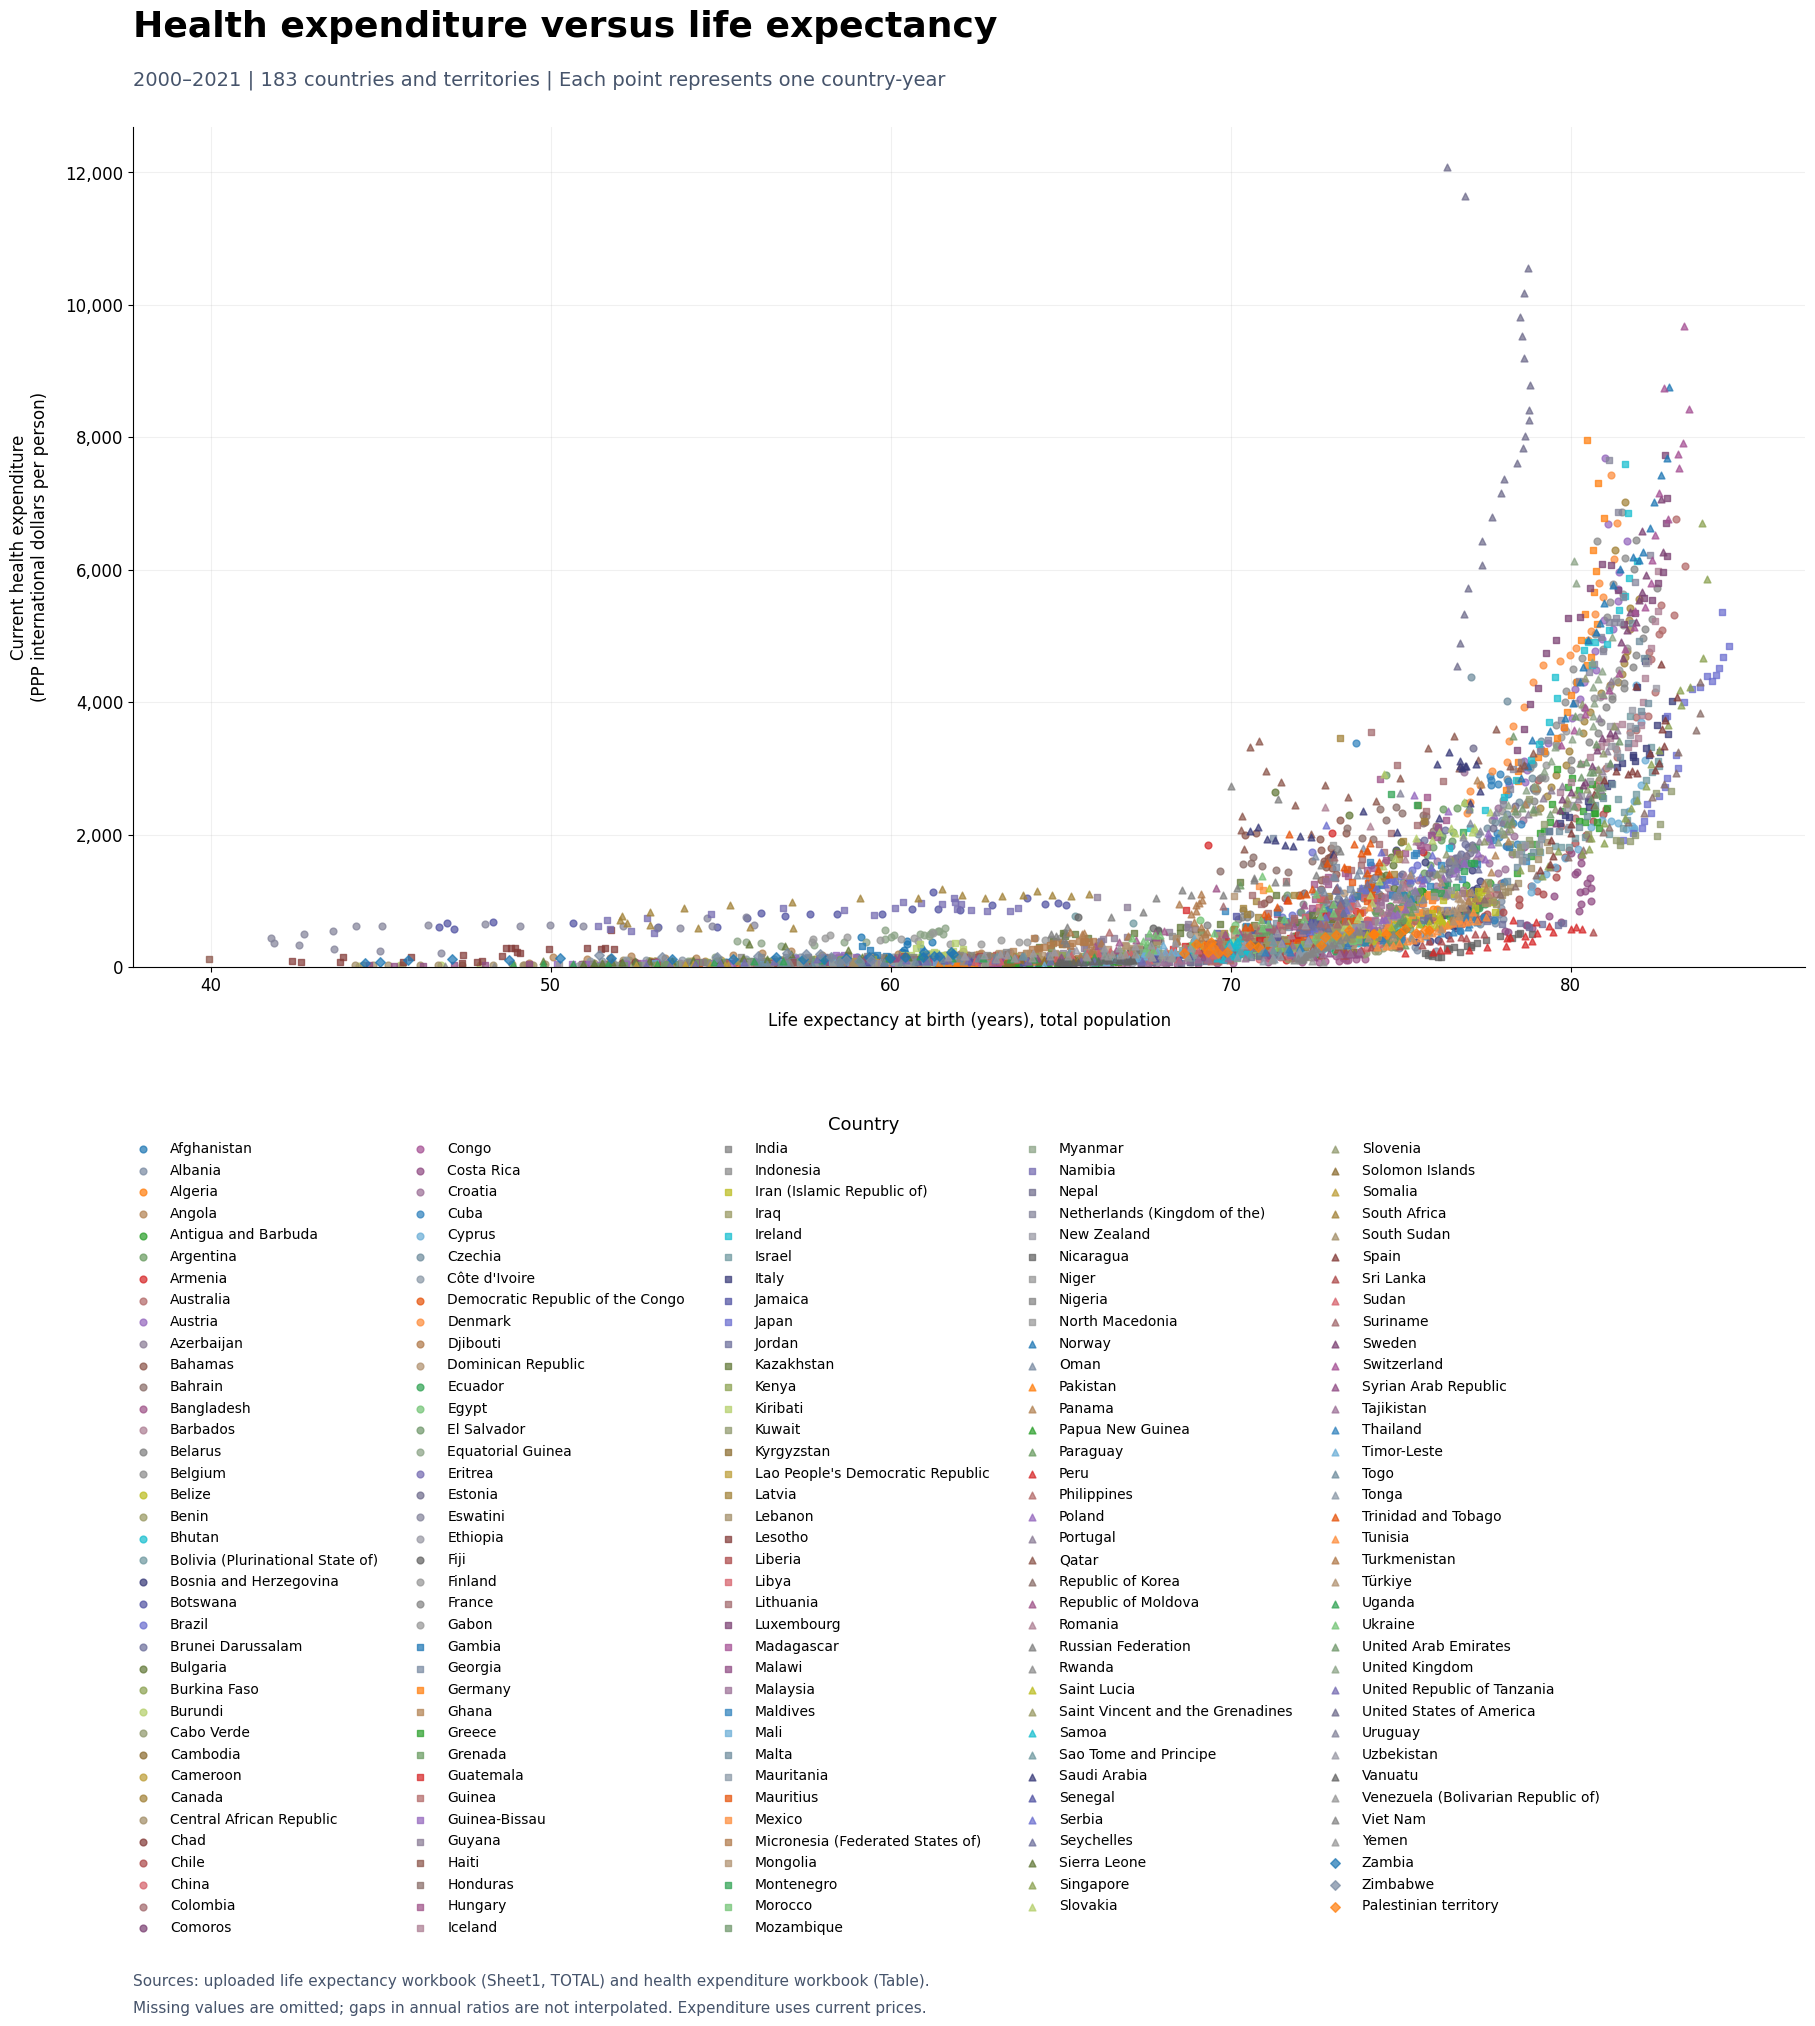

In [4]:
scatter_path = create_plot('scatter')


## 2. Life expectancy per health expenditure over time

Each line represents one country or territory. The y-axis is logarithmic; equal vertical distances indicate equal proportional changes.


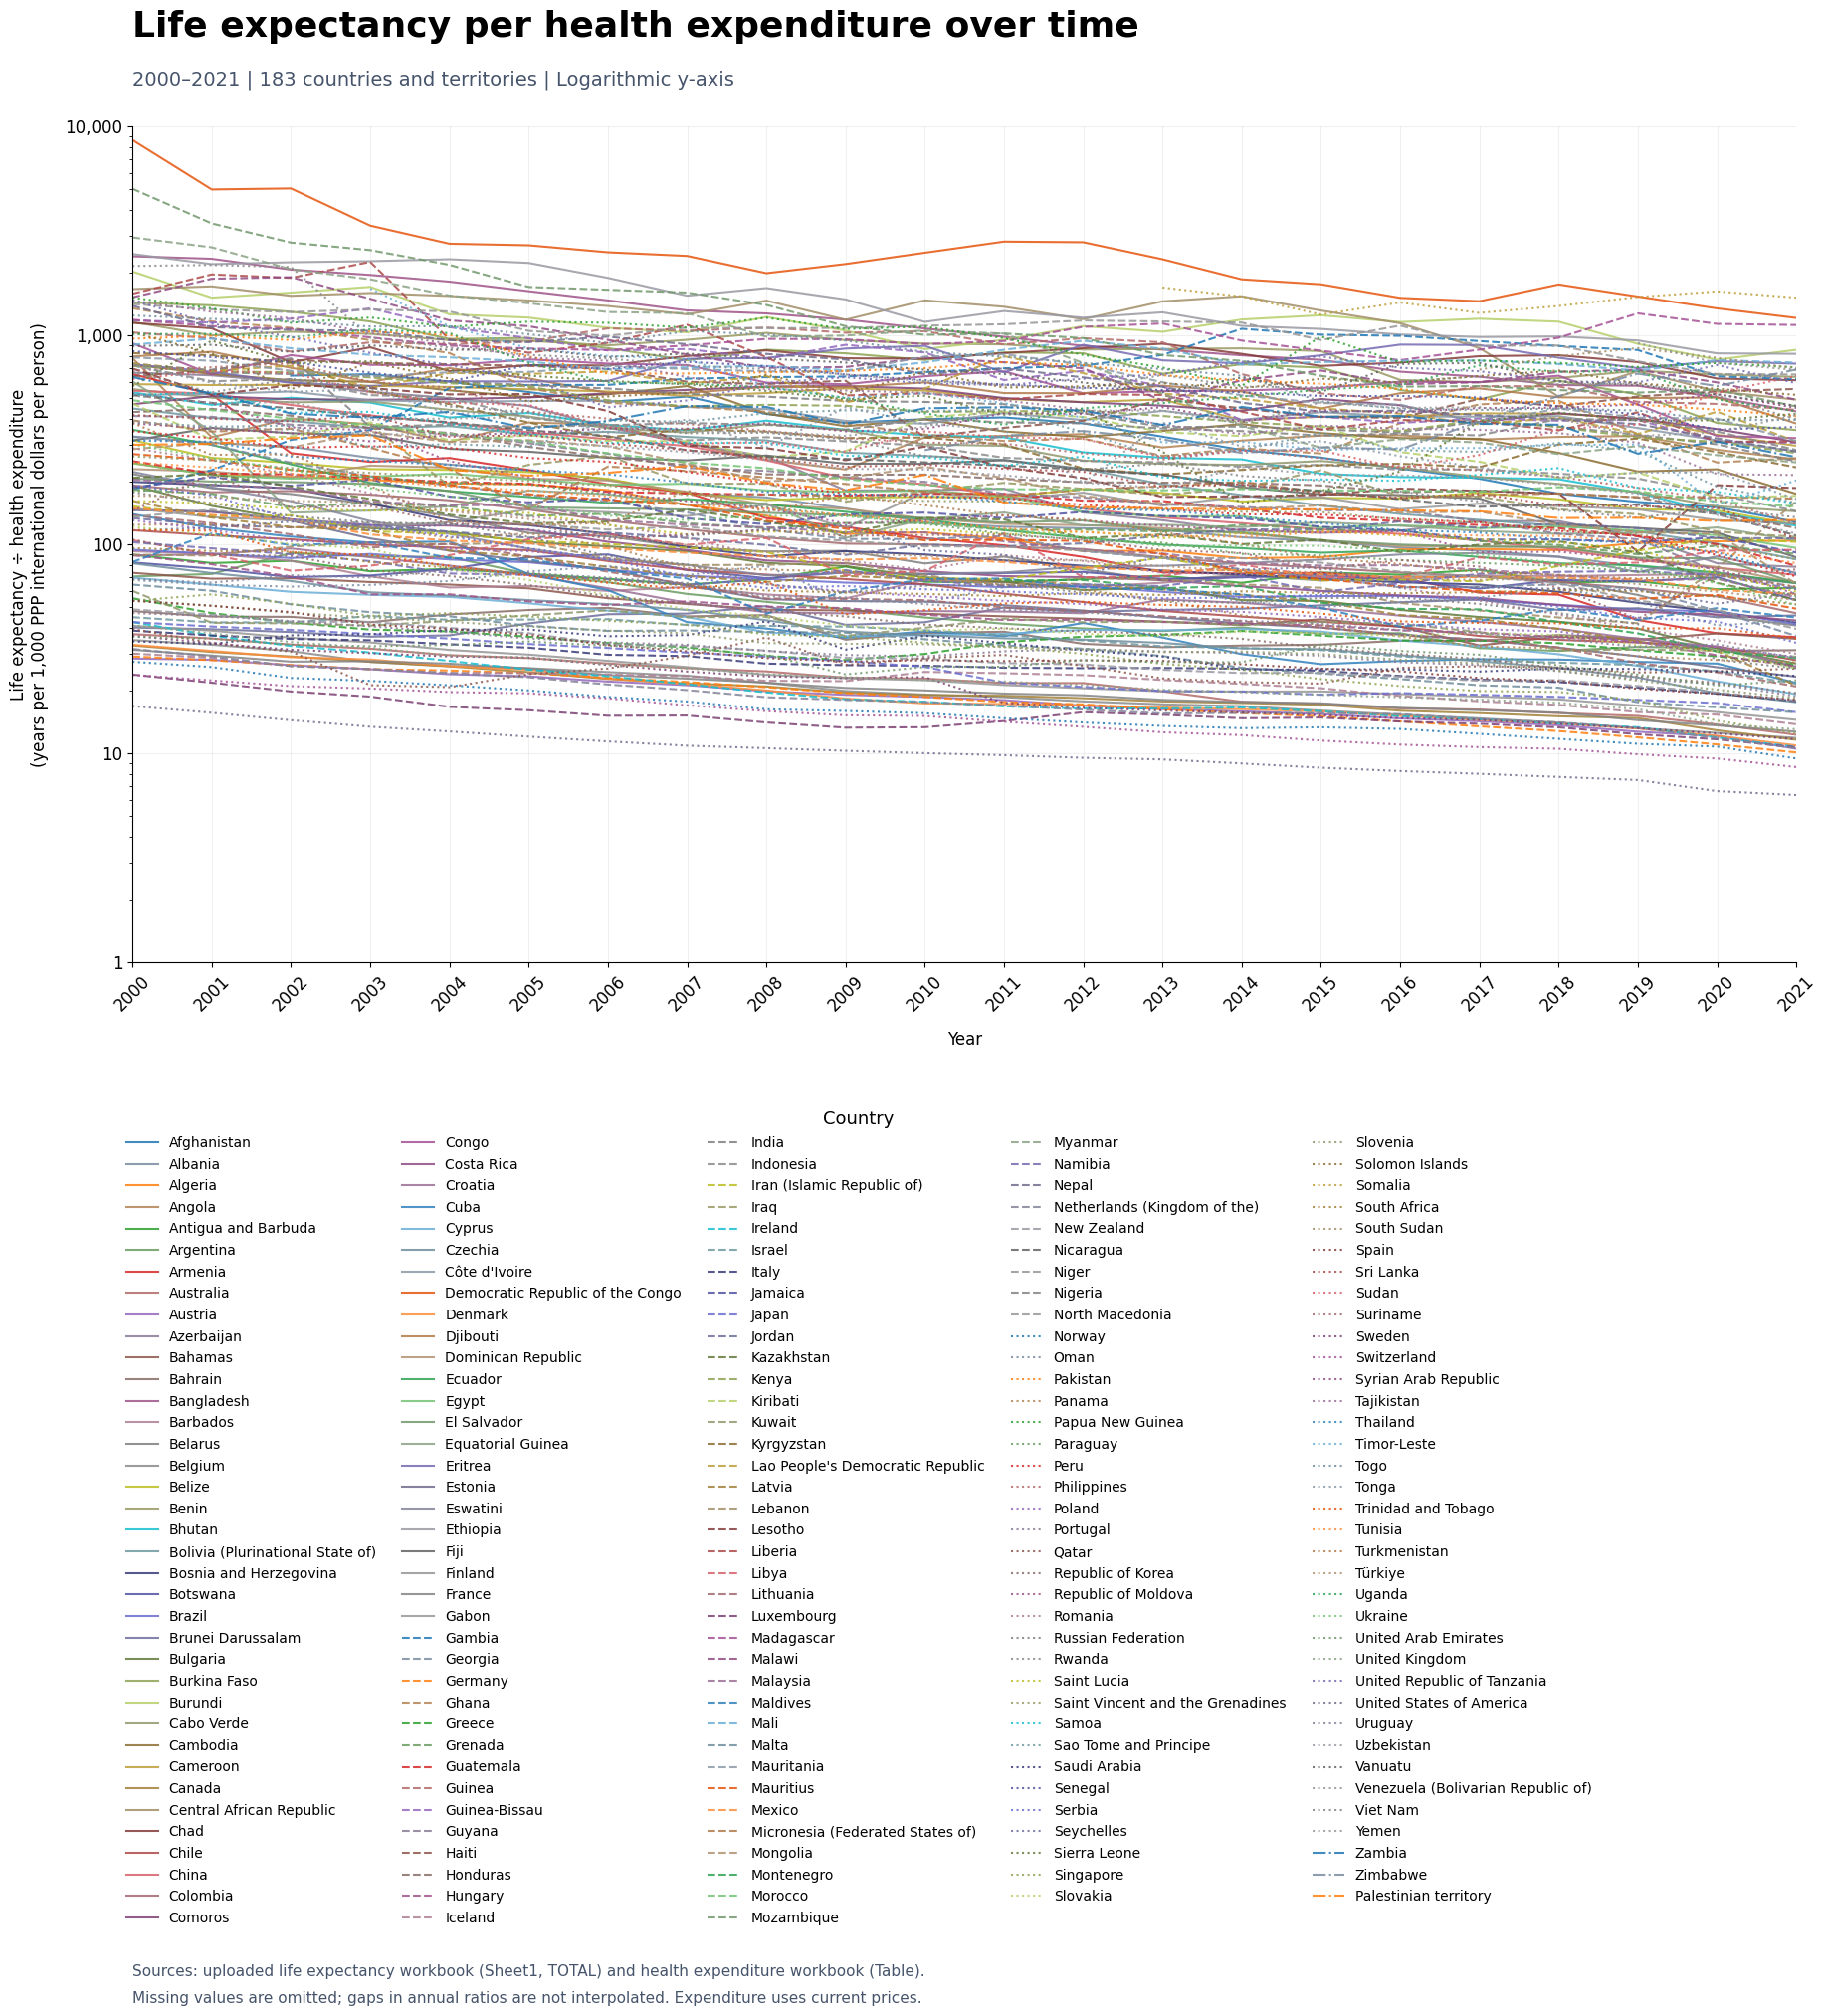

In [5]:
ratio_path = create_plot('ratio')


## Download both plots

Run this optional cell to download a ZIP containing both PNG files.


In [6]:
'''import zipfile
with zipfile.ZipFile("life_expectancy_health_expenditure_plots.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in [scatter_path, ratio_path]:
        archive.write(path, arcname=path.name)
files.download("life_expectancy_health_expenditure_plots.zip")'''


'import zipfile\nwith zipfile.ZipFile("life_expectancy_health_expenditure_plots.zip", "w", zipfile.ZIP_DEFLATED) as archive:\n    for path in [scatter_path, ratio_path]:\n        archive.write(path, arcname=path.name)\nfiles.download("life_expectancy_health_expenditure_plots.zip")'

In [7]:
#Spearman and Pearson Tests
corr_df = df[[life_col, expenditure_col]].dropna()

r_p, p_p = pearsonr(
    corr_df[expenditure_col],
    corr_df[life_col]
)

r_s, p_s = spearmanr(
    corr_df[expenditure_col],
    corr_df[life_col]
)

print(f"Pearson r = {r_p:.4f}")
print(f"Pearson p = {p_p:.4e}")
print(f"Spearman rho = {r_s:.4f}")
print(f"Spearman p = {p_s:.4e}")

model_df = df[[life_col, expenditure_col]].dropna()

# Linear
X1 = sm.add_constant(model_df[expenditure_col])
linear_model = sm.OLS(model_df[life_col], X1).fit()

# Log
X2 = sm.add_constant(np.log(model_df[expenditure_col]))
log_model = sm.OLS(model_df[life_col], X2).fit()

print("Linear R²:", linear_model.rsquared)
print("Log R²:", log_model.rsquared)


Pearson r = 0.6306
Pearson p = 0.0000e+00
Spearman rho = 0.8617
Spearman p = 0.0000e+00
Linear R²: 0.3976183398310804
Log R²: 0.6682485226654283


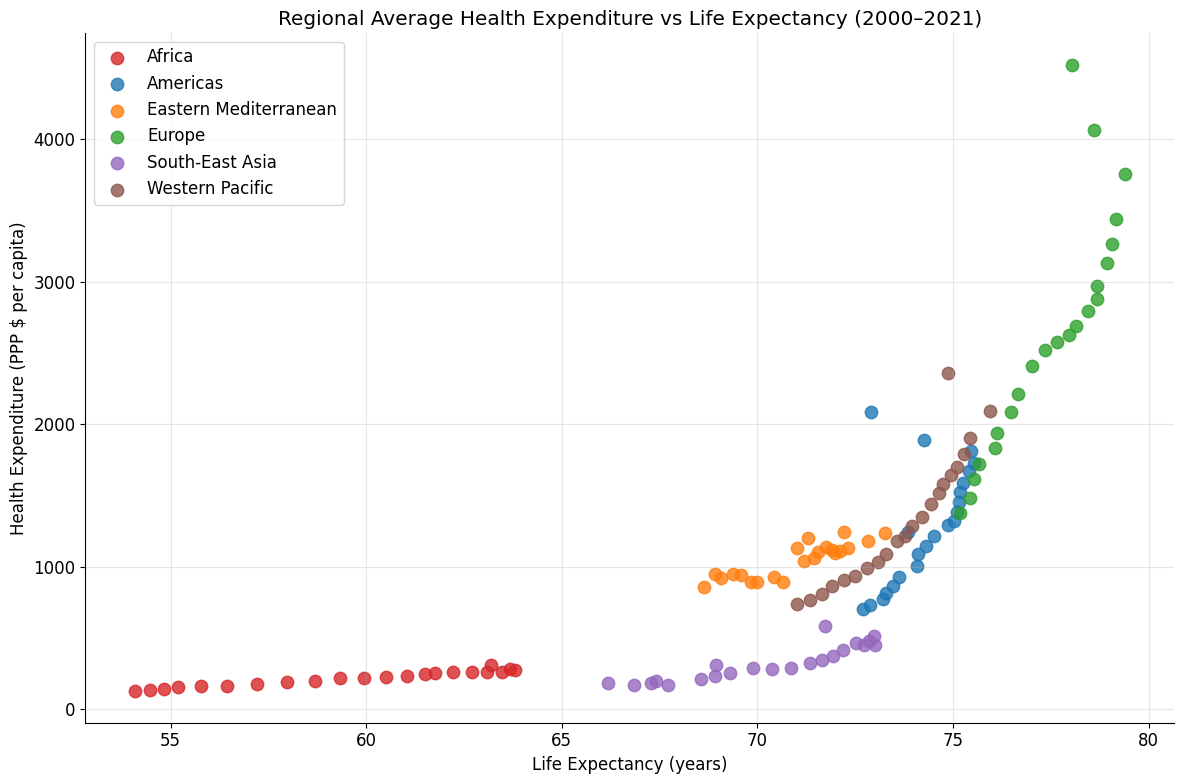

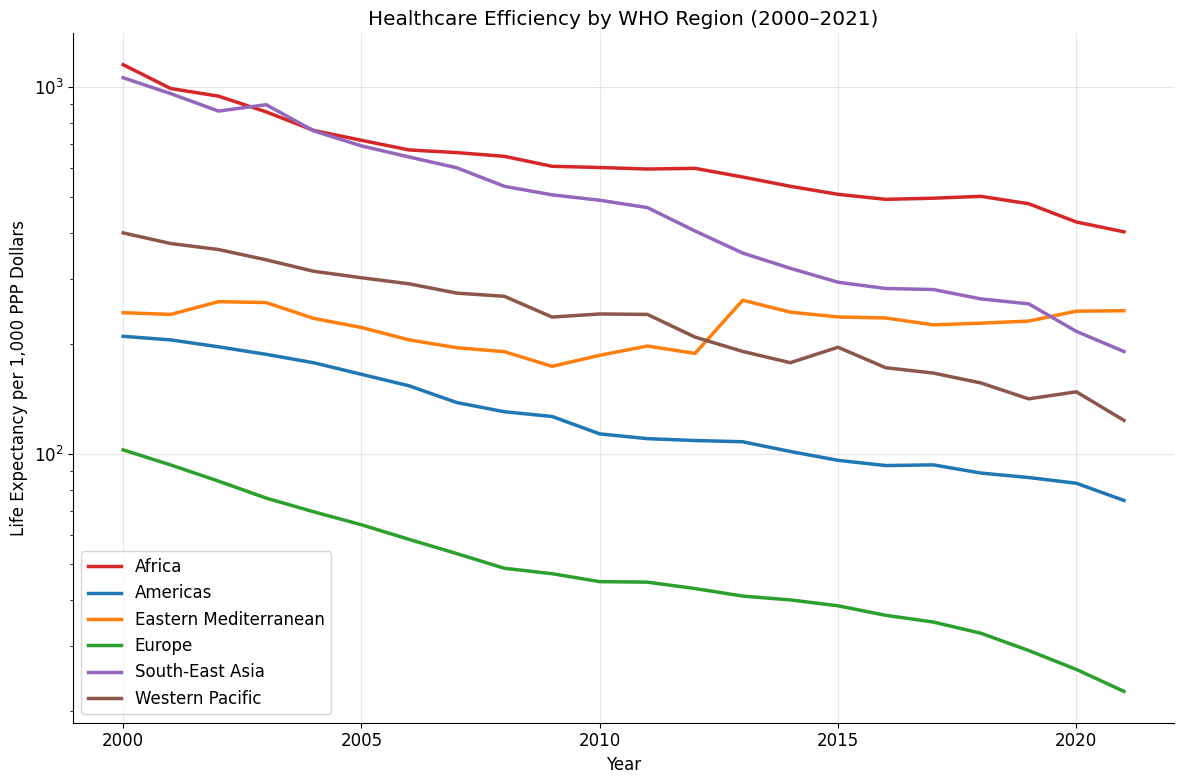

In [8]:
# ==========================
# WHO REGION ANALYSIS PLOTS
# ==========================

life_col = "Life expectancy at birth (years), total population"
expenditure_col = "Current health expenditure (PPP international dollars per capita)"
ratio_col = "Life expectancy / expenditure (years per 1000 PPP international dollars per capita)"

# WHO regional assignments
region_map = {
    # Africa
    "Algeria":"Africa","Angola":"Africa","Benin":"Africa","Botswana":"Africa",
    "Burkina Faso":"Africa","Burundi":"Africa","Cameroon":"Africa",
    "Cape Verde":"Africa","Central African Republic":"Africa","Chad":"Africa",
    "Comoros":"Africa","Congo":"Africa","Côte d'Ivoire":"Africa",
    "Democratic Republic of the Congo":"Africa","Djibouti":"Africa",
    "Egypt":"Africa","Equatorial Guinea":"Africa","Eritrea":"Africa",
    "Eswatini":"Africa","Ethiopia":"Africa","Gabon":"Africa","Gambia":"Africa",
    "Ghana":"Africa","Guinea":"Africa","Guinea-Bissau":"Africa",
    "Kenya":"Africa","Lesotho":"Africa","Liberia":"Africa","Libya":"Africa",
    "Madagascar":"Africa","Malawi":"Africa","Mali":"Africa","Mauritania":"Africa",
    "Mauritius":"Africa","Morocco":"Africa","Mozambique":"Africa",
    "Namibia":"Africa","Niger":"Africa","Nigeria":"Africa","Rwanda":"Africa",
    "Senegal":"Africa","Sierra Leone":"Africa","Somalia":"Africa",
    "South Africa":"Africa","South Sudan":"Africa","Sudan":"Africa",
    "Tanzania":"Africa","Togo":"Africa","Tunisia":"Africa","Uganda":"Africa",
    "Zambia":"Africa","Zimbabwe":"Africa",

    # Americas
    "Argentina":"Americas","Bahamas":"Americas","Barbados":"Americas",
    "Belize":"Americas","Bolivia":"Americas","Brazil":"Americas",
    "Canada":"Americas","Chile":"Americas","Colombia":"Americas",
    "Costa Rica":"Americas","Cuba":"Americas","Dominican Republic":"Americas",
    "Ecuador":"Americas","El Salvador":"Americas","Guatemala":"Americas",
    "Guyana":"Americas","Haiti":"Americas","Honduras":"Americas",
    "Jamaica":"Americas","Mexico":"Americas","Nicaragua":"Americas",
    "Panama":"Americas","Paraguay":"Americas","Peru":"Americas",
    "Suriname":"Americas","Trinidad and Tobago":"Americas",
    "United States of America":"Americas","Uruguay":"Americas",
    "Venezuela":"Americas",

    # Europe
    "Albania":"Europe","Austria":"Europe","Belarus":"Europe","Belgium":"Europe",
    "Bosnia and Herzegovina":"Europe","Bulgaria":"Europe","Croatia":"Europe",
    "Cyprus":"Europe","Czechia":"Europe","Denmark":"Europe","Estonia":"Europe",
    "Finland":"Europe","France":"Europe","Germany":"Europe","Greece":"Europe",
    "Hungary":"Europe","Iceland":"Europe","Ireland":"Europe","Italy":"Europe",
    "Latvia":"Europe","Lithuania":"Europe","Luxembourg":"Europe",
    "Malta":"Europe","Moldova":"Europe","Montenegro":"Europe",
    "Netherlands":"Europe","North Macedonia":"Europe","Norway":"Europe",
    "Poland":"Europe","Portugal":"Europe","Romania":"Europe",
    "Russian Federation":"Europe","Serbia":"Europe","Slovakia":"Europe",
    "Slovenia":"Europe","Spain":"Europe","Sweden":"Europe",
    "Switzerland":"Europe","Ukraine":"Europe",
    "United Kingdom of Great Britain and Northern Ireland":"Europe",

    # Eastern Mediterranean
    "Afghanistan":"Eastern Mediterranean","Bahrain":"Eastern Mediterranean",
    "Iran":"Eastern Mediterranean","Iraq":"Eastern Mediterranean",
    "Jordan":"Eastern Mediterranean","Kuwait":"Eastern Mediterranean",
    "Lebanon":"Eastern Mediterranean","Libya":"Eastern Mediterranean",
    "Oman":"Eastern Mediterranean","Pakistan":"Eastern Mediterranean",
    "Qatar":"Eastern Mediterranean","Saudi Arabia":"Eastern Mediterranean",
    "Somalia":"Eastern Mediterranean","Sudan":"Eastern Mediterranean",
    "Syrian Arab Republic":"Eastern Mediterranean","Tunisia":"Eastern Mediterranean",
    "United Arab Emirates":"Eastern Mediterranean","Yemen":"Eastern Mediterranean",
    "occupied Palestinian territory, including east Jerusalem":"Eastern Mediterranean",

    # South-East Asia
    "Bangladesh":"South-East Asia","Bhutan":"South-East Asia",
    "India":"South-East Asia","Indonesia":"South-East Asia",
    "Maldives":"South-East Asia","Myanmar":"South-East Asia",
    "Nepal":"South-East Asia","Sri Lanka":"South-East Asia",
    "Thailand":"South-East Asia","Timor-Leste":"South-East Asia",

    # Western Pacific
    "Australia":"Western Pacific","Brunei Darussalam":"Western Pacific",
    "Cambodia":"Western Pacific","China":"Western Pacific",
    "Fiji":"Western Pacific","Japan":"Western Pacific",
    "Lao People's Democratic Republic":"Western Pacific",
    "Malaysia":"Western Pacific","Mongolia":"Western Pacific",
    "New Zealand":"Western Pacific","Papua New Guinea":"Western Pacific",
    "Philippines":"Western Pacific","Republic of Korea":"Western Pacific",
    "Singapore":"Western Pacific","Viet Nam":"Western Pacific"
}

# Create region column
df["Region"] = df["Country"].map(region_map)

# Remove countries not mapped
regional_df = df.dropna(subset=["Region"]).copy()

# Calculate yearly regional means
regional_avg = (
    regional_df
    .groupby(["Region","Year"])
    [[life_col, expenditure_col, ratio_col]]
    .mean()
    .reset_index()
)

region_colors = {
    "Africa":"#D62728",
    "Americas":"#1F77B4",
    "Europe":"#2CA02C",
    "Eastern Mediterranean":"#FF7F0E",
    "South-East Asia":"#9467BD",
    "Western Pacific":"#8C564B"
}

# -------------------------
# Scatter Plot
# -------------------------
plt.figure(figsize=(12,8))

for region in regional_avg["Region"].unique():
    temp = regional_avg[regional_avg["Region"] == region]

    plt.scatter(
        temp[life_col],
        temp[expenditure_col],
        s=80,
        alpha=0.8,
        color=region_colors[region],
        label=region
    )

plt.xlabel("Life Expectancy (years)")
plt.ylabel("Health Expenditure (PPP $ per capita)")
plt.title("Regional Average Health Expenditure vs Life Expectancy (2000–2021)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------------
# Ratio Time Series Plot
# -------------------------
plt.figure(figsize=(12,8))

for region in regional_avg["Region"].unique():
    temp = regional_avg[regional_avg["Region"] == region]

    plt.plot(
        temp["Year"],
        temp[ratio_col],
        linewidth=2.5,
        color=region_colors[region],
        label=region
    )

plt.yscale("log")
plt.xlabel("Year")
plt.ylabel("Life Expectancy per 1,000 PPP Dollars")
plt.title("Healthcare Efficiency by WHO Region (2000–2021)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
#Creation of a clean dataframe for analysis using statistical models
model_df = df[
    [life_col, expenditure_col, "Country", "Region"]
].dropna()

model_df = model_df[
    model_df[expenditure_col] > 0
].copy()

In [10]:
#Model 1, Overall effect of healthcare spending - question being answered = is healthcare spending assoctaed with life expectancy globally
model1 = mixedlm(
    f'Q("{life_col}") ~ np.log(Q("{expenditure_col}"))',
    data=model_df,
    groups=model_df["Country"]
)

result1 = model1.fit()

print("="*60)
print("MODEL 1: GLOBAL SPENDING EFFECT")
print("="*60)
print(result1.summary())
#This model estimates life expectancy = beta0 + beta1 ln(healthcare spending) and accounts for repeated measurments within countires

#Model 2, Spending + regional diffrences - question being answered = after accounting for spending, do WHO regions differ?
model2 = mixedlm(
    f'Q("{life_col}") ~ np.log(Q("{expenditure_col}")) + C(Region)',
    data=model_df,
    groups=model_df["Country"]
)

result2 = model2.fit()

print("="*60)
print("MODEL 2: SPENDING + REGION")
print("="*60)
print(result2.summary())
#This model estemates life expectancy = beta0 + beta1 ln(healthcare spending) + beta2 Region
#This tests the effect of spending and whether regions differ in baseline life expectancy

#Model 3, spending x regional interaction - question being answered = Does healthcare spending have diffrent effects in diffrent regions?
model3 = mixedlm(
    f'Q("{life_col}") ~ np.log(Q("{expenditure_col}")) * C(Region)',
    data=model_df,
    groups=model_df["Country"]
)

result3 = model3.fit()

print("="*60)
print("MODEL 3: SPENDING × REGION INTERACTION")
print("="*60)
print(result3.summary())

#This model estimates beta0 + beta1 ln(healthcare spending) + beta2 Region + Beta 3 ((ln(spending x region)))
#This model answers if spending matters, do regions differ and do regions repsond diffrenty to increased spending
result1 = model1.fit(reml=False)
result2 = model2.fit(reml=False)
result3 = model3.fit(reml=False)
print(f"Model 1 AIC: {result1.aic:.2f}")
print(f"Model 2 AIC: {result2.aic:.2f}")
print(f"Model 3 AIC: {result3.aic:.2f}")

MODEL 1: GLOBAL SPENDING EFFECT
                                          Mixed Linear Model Regression Results
Model:                    MixedLM       Dependent Variable:       Q("Life expectancy at birth (years), total population")
No. Observations:         3329          Method:                   REML                                                   
No. Groups:               154           Scale:                    3.8898                                                 
Min. group size:          5             Log-Likelihood:           -7361.7503                                             
Max. group size:          22            Converged:                Yes                                                    
Mean group size:          21.6                                                                                           
-------------------------------------------------------------------------------------------------------------------------
                                  

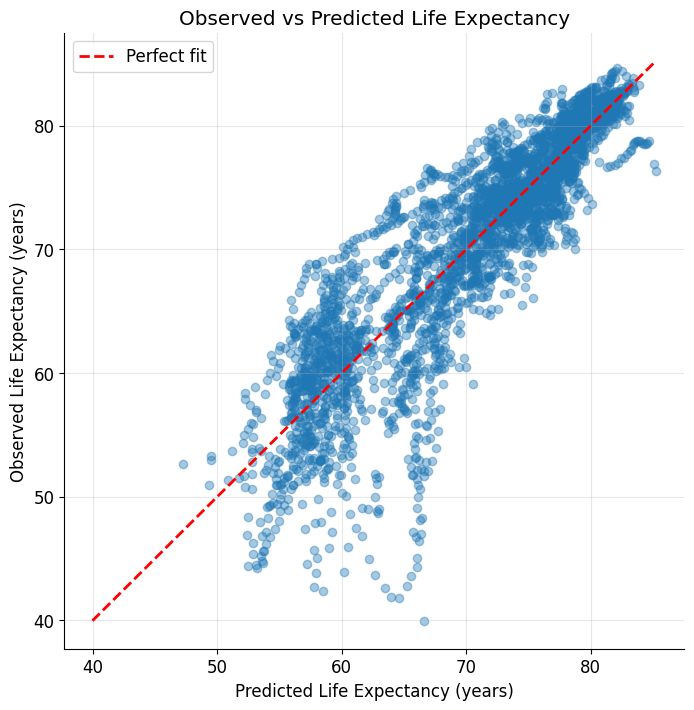

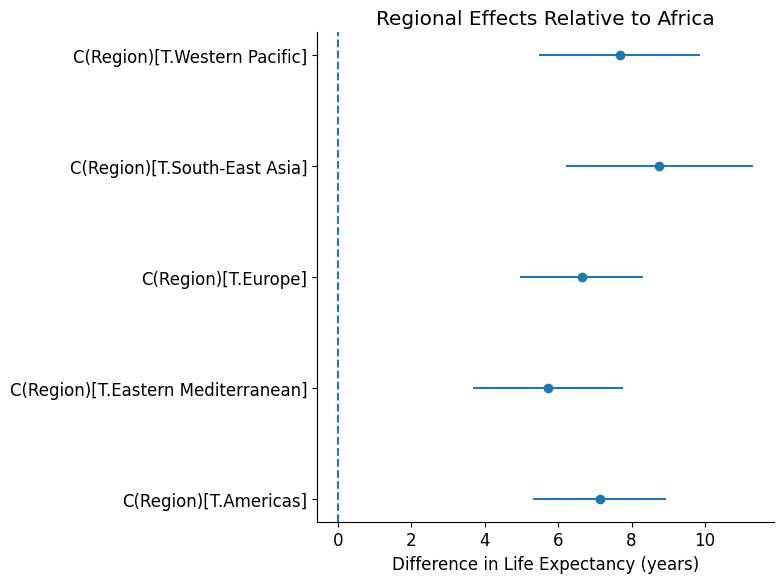

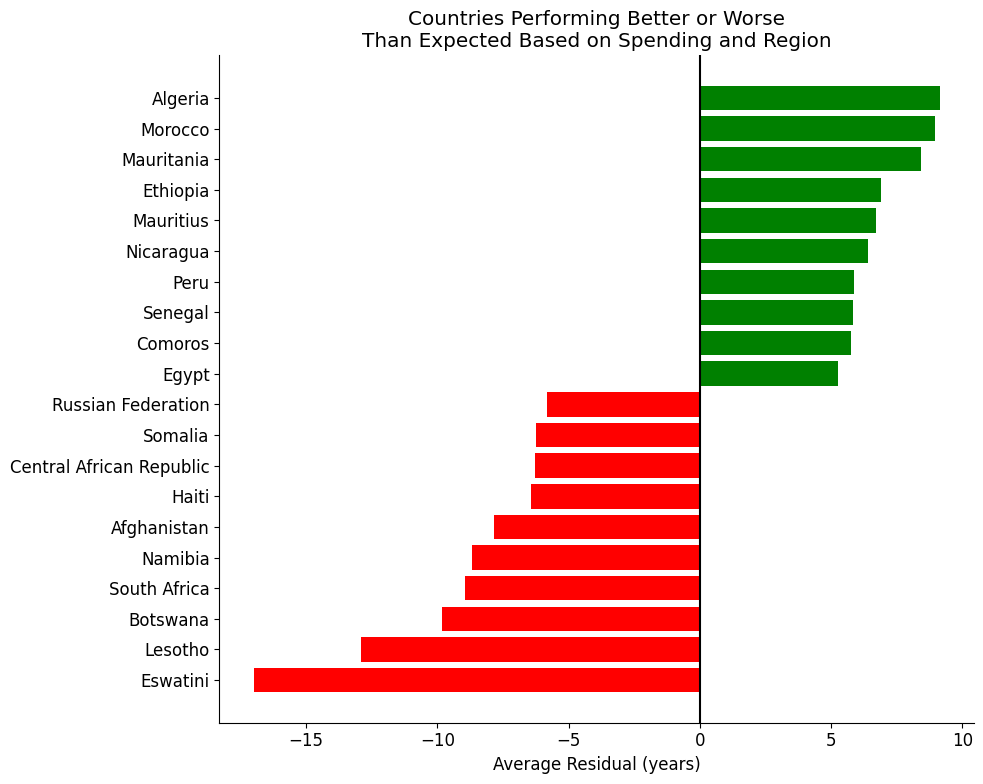

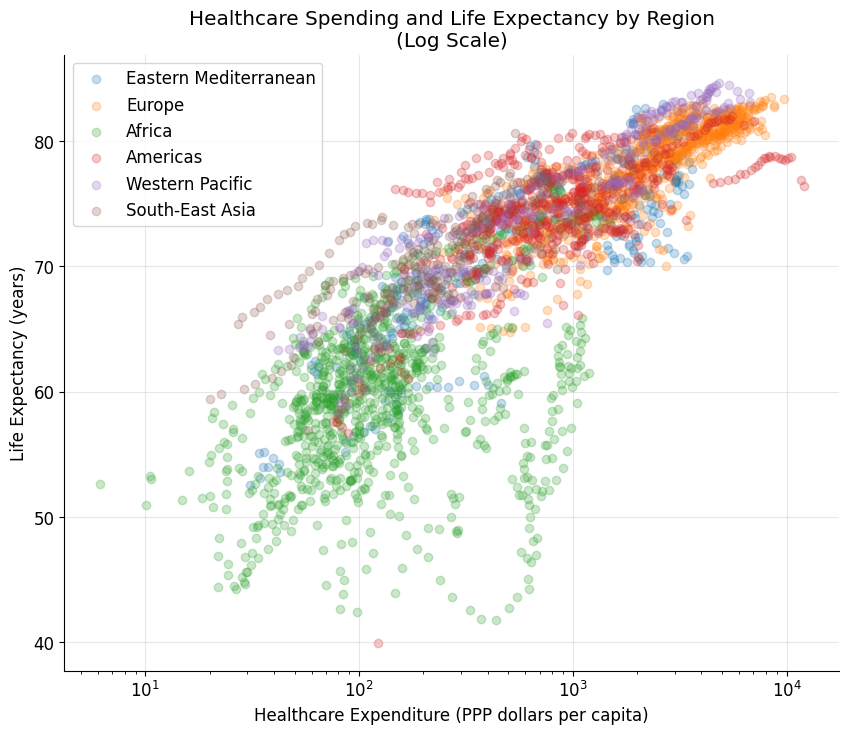

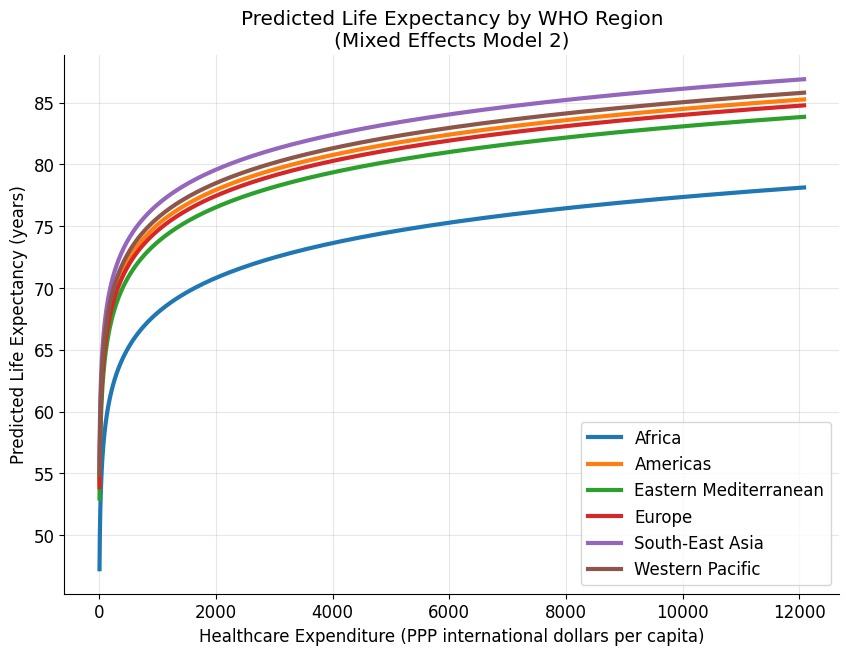

In [11]:
#Visualizations based on fit models
# Generate predictions
model_df["Predicted_LE"] = result2.predict(model_df)

plt.figure(figsize=(8,8))

plt.scatter(
    model_df["Predicted_LE"],
    model_df[life_col],
    alpha=0.4
)

# Perfect prediction line
min_val = min(
    model_df["Predicted_LE"].min(),
    model_df[life_col].min()
)

max_val = max(
    model_df["Predicted_LE"].max(),
    model_df[life_col].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    linewidth=2,
    label='Perfect fit'
)

plt.xlabel("Predicted Life Expectancy (years)")
plt.ylabel("Observed Life Expectancy (years)")
plt.title("Observed vs Predicted Life Expectancy")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



coef_names = [
    name for name in result2.params.index
    if "Region" in name
]

coef_values = [
    result2.params[name]
    for name in coef_names
]

conf = result2.conf_int()

lower = [
    conf.loc[name, 0]
    for name in coef_names
]

upper = [
    conf.loc[name, 1]
    for name in coef_names
]

plt.figure(figsize=(8,6))

plt.errorbar(
    coef_values,
    range(len(coef_names)),
    xerr=[
        np.array(coef_values) - np.array(lower),
        np.array(upper) - np.array(coef_values)
    ],
    fmt='o'
)

plt.axvline(0, linestyle='--')

plt.yticks(range(len(coef_names)), coef_names)

plt.xlabel("Difference in Life Expectancy (years)")
plt.title("Regional Effects Relative to Africa")

plt.tight_layout()
plt.show()



model_df["Residual"] = (
    model_df[life_col]
    - model_df["Predicted_LE"]
)

country_residuals = (
    model_df
    .groupby("Country")["Residual"]
    .mean()
    .sort_values()
)
top10 = country_residuals.tail(10)
bottom10 = country_residuals.head(10)

plot_data = pd.concat([bottom10, top10])

plt.figure(figsize=(10,8))

colors = [
    'red' if x < 0 else 'green'
    for x in plot_data.values
]

plt.barh(
    plot_data.index,
    plot_data.values,
    color=colors
)

plt.axvline(0, color='black')

plt.xlabel("Average Residual (years)")
plt.title(
    "Countries Performing Better or Worse\n"
    "Than Expected Based on Spending and Region"
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(10,8))

for region in model_df["Region"].unique():

    temp = model_df[
        model_df["Region"] == region
    ]

    plt.scatter(
        temp[expenditure_col],
        temp[life_col],
        alpha=0.25,
        label=region
    )

plt.xscale("log")

plt.xlabel("Healthcare Expenditure (PPP dollars per capita)")
plt.ylabel("Life Expectancy (years)")
plt.title(
    "Healthcare Spending and Life Expectancy by Region\n"
    "(Log Scale)"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()


# Create spending range
x_vals = np.logspace(
    np.log10(model_df[expenditure_col].min()),
    np.log10(model_df[expenditure_col].max()),
    200
)

regions = sorted(model_df["Region"].unique())

plt.figure(figsize=(10,7))

for region in regions:

    pred_df = pd.DataFrame({
        expenditure_col: x_vals,
        "Region": region,
        "Country": model_df["Country"].iloc[0]
    })

    y_pred = result2.predict(pred_df)

    plt.plot(
        x_vals,
        y_pred,
        linewidth=3,
        label=region
    )

#plt.xscale("log")
plt.xlabel("Healthcare Expenditure (PPP international dollars per capita)")
plt.ylabel("Predicted Life Expectancy (years)")

plt.title(
    "Predicted Life Expectancy by WHO Region\n"
    "(Mixed Effects Model 2)"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()